In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split

# 1. Cargar el dataset depurado de docentes
df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv")
df.columns = df.columns.str.lower().str.strip()
df = df.loc[:, ~df.columns.duplicated()]

col_edad = "eda" if "eda" in df.columns else "eda_x"

# 2. Definir variables y asegurar tipos enteros para categóricas
cols_categoricas = ["sex", "cs_p13_1", "p3a"]
cols_numericas = ["hrsocup", col_edad, "ingocup"]
cols_totales = cols_numericas + cols_categoricas

for col in cols_totales:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df_model = df.dropna(subset=cols_totales).copy()
df_model = df_model[(df_model["ingocup"] > 0) & (df_model["hrsocup"] > 0)]

# Convertir categóricas a enteros para evitar decimales (.0) en One-Hot Encoding
for col in cols_categoricas:
    df_model[col] = df_model[col].astype(int)

# 3. One-Hot Encoding
df_encoded = pd.get_dummies(
    df_model[cols_totales], columns=cols_categoricas, drop_first=True
)
df_encoded = df_encoded.loc[:, ~df_encoded.columns.duplicated()]

X = df_encoded.drop(columns=["ingocup"])
y = df_encoded["ingocup"]

# 4. Diccionario de Traducción Intuitiva Completo
nombres_shap_publico = {
    "hrsocup": "Jornada Laboral (Horas/Semana)",
    col_edad: "Edad y Experiencia (Años)",
    "sex_2": "Brecha de Género: Docente Mujer",
    "p3a_2": "Empleo en Sector Privado / Informal",
    "cs_p13_1_2": "Escolaridad: Primaria",
    "cs_p13_1_3": "Escolaridad: Secundaria",
    "cs_p13_1_4": "Escolaridad: Preparatoria / Bachillerato",
    "cs_p13_1_5": "Escolaridad: Carrera Técnica",
    "cs_p13_1_6": "Nivel Educativo: Licenciatura",
    "cs_p13_1_7": "Nivel Educativo: Maestría",
    "cs_p13_1_8": "Nivel Educativo: Doctorado",
    "cs_p13_1_9": "Escolaridad: No Especificado",
}

# Renombrar columnas en la matriz X
X = X.rename(columns=nombres_shap_publico)

# 5. División Train / Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Entrenar el Modelo Ganador (Gradient Boosting con Huber Loss)
modelo_gb = GradientBoostingRegressor(
    loss="huber", n_estimators=100, learning_rate=0.05, random_state=42
)
modelo_gb.fit(X_train, y_train)

print(
    " Modelo Gradient Boosting entrenado con diccionario completo (Secundaria corregida)."
)

 Modelo Gradient Boosting entrenado con diccionario completo (Secundaria corregida).


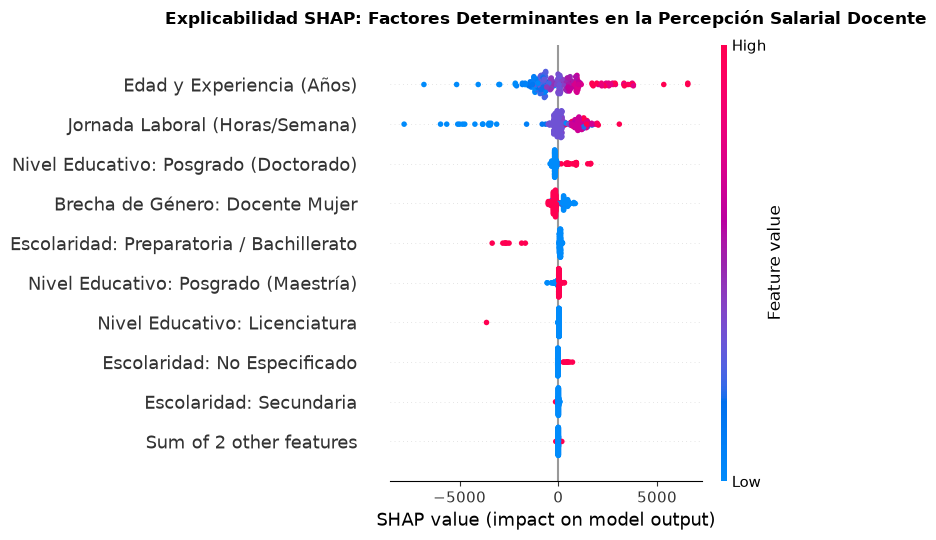

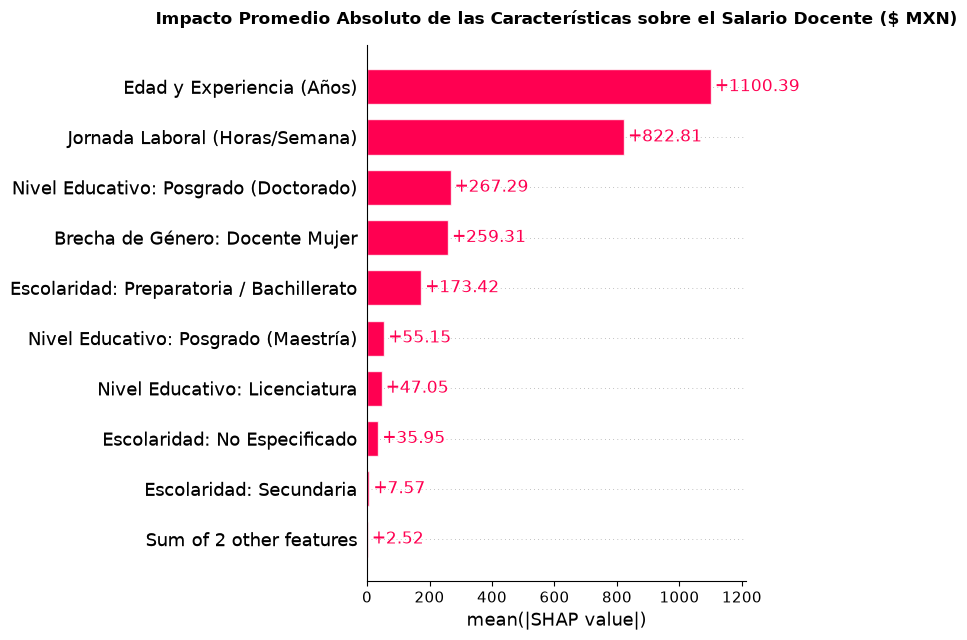

In [8]:
# 1. Explicador SHAP
explainer = shap.TreeExplainer(modelo_gb)
shap_values = explainer(X_test)

os.makedirs("../outputs/figures", exist_ok=True)

# 2. Gráfica Beeswarm
plt.figure(figsize=(11, 6))
plt.title(
    "Explicabilidad SHAP: Factores Determinantes en la Percepción Salarial Docente",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
shap.plots.beeswarm(shap_values, show=False)
plt.tight_layout()
plt.savefig("../outputs/figures/shap_summary_beeswarm.png", dpi=300)
plt.show()

# 3. Gráfica de Importancia Promedio
plt.figure(figsize=(11, 5))
plt.title(
    "Impacto Promedio Absoluto de las Características sobre el Salario Docente ($ MXN)",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
shap.plots.bar(shap_values, show=False)
plt.tight_layout()
plt.savefig("../outputs/figures/shap_feature_importance.png", dpi=300)
plt.show()

=== ANÁLISIS INDIVIDUAL DEL DOCENTE #0 ===
Salario Real reportado: $15,000.00 MXN
Salario Predicho por el Modelo: $13,852.72 MXN



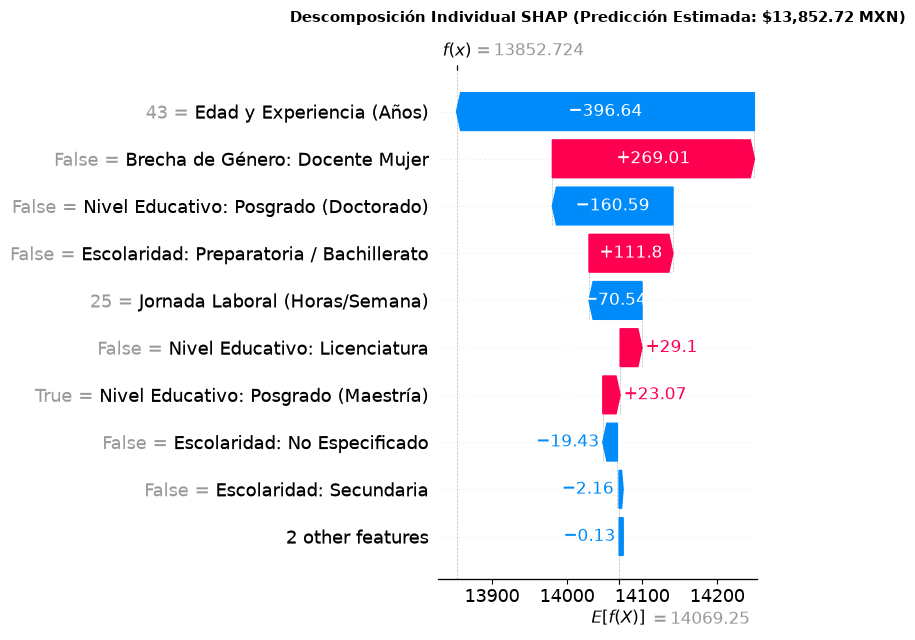

In [9]:
# 1. Seleccionar un caso de estudio (ej. el docente con índice 0 en X_test)
idx_docente = 0
docente_ejemplo = X_test.iloc[[idx_docente]]
salario_real = y_test.iloc[idx_docente]
salario_pred = modelo_gb.predict(docente_ejemplo)[0]

print(f"=== ANÁLISIS INDIVIDUAL DEL DOCENTE #{idx_docente} ===")
print(f"Salario Real reportado: ${salario_real:,.2f} MXN")
print(f"Salario Predicho por el Modelo: ${salario_pred:,.2f} MXN\n")

# 2. Gráfica de Cascada (Waterfall Plot) para el caso individual
plt.figure(figsize=(10, 5.5))
plt.title(
    f"Descomposición Individual SHAP (Predicción Estimada: ${salario_pred:,.2f} MXN)",
    fontsize=11,
    fontweight="bold",
    pad=15,
)
shap.plots.waterfall(shap_values[idx_docente], show=False)
plt.tight_layout()
plt.savefig("../outputs/figures/shap_waterfall_individual.png", dpi=300)
plt.show()